# BDA112 Assignment 2 – Urban Air Quality Analytics

## Air Quality Analysis – Randwick, Sydney

This notebook will be analysing data on air quality collected using OpenAQ at the Randwick monitoring station in Sydney. The analysis will be based on particulate matter and environmental data such as PM1, PM2.5, relative humidity, temperature, and number of PM0.3 particles.

This notebook will contain data processing, exploratory data analysis (EDA), visualisation, and predictive modelling. PM2.5 will be used as the target variable for prediction.

In [1]:
# BDA112 Assignment 2 - Urban Air Quality Analytics

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


Importing of Python modules that were necessary was done and loading of the OpenAQ air quality dataset for the area of Randwick in a Pandas DataFrame was also carried out. The dataset was examined to learn about its size, features, data types, and available air quality indicators.

In [2]:
# Load the OpenAQ air quality dataset

df = pd.read_csv(r"C:\Users\nisch\Downloads\openaq_location_6521091_measurments (1).csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (1730, 15)


,location_id,location_name,parameter,value,unit,datetimeUtc,datetimeLocal,timezone,latitude,longitude,country_iso,isMobile,isMonitor,owner_name,provider
0,6521091,Randwick,pm1,0.0,µg/m³,2026-09-03T06:00:00Z,2026-09-03T16:00:00+10:00,Australia/Sydney,-33.9136,151.2424,NaN,NaN,NaN,AirGradient,AirGradient
1,6521091,Randwick,pm1,0.0,µg/m³,2026-09-03T08:00:00Z,2026-09-03T18:00:00+10:00,Australia/Sydney,-33.9136,151.2424,NaN,NaN,NaN,AirGradient,AirGradient
2,6521091,Randwick,pm1,0.0,µg/m³,2026-09-03T09:00:00Z,2026-09-03T19:00:00+10:00,Australia/Sydney,-33.9136,151.2424,NaN,NaN,NaN,AirGradient,AirGradient
3,6521091,Randwick,pm1,0.1,µg/m³,2026-09-03T10:00:00Z,2026-09-03T20:00:00+10:00,Australia/Sydney,-33.9136,151.2424,NaN,NaN,NaN,AirGradient,AirGradient
4,6521091,Randwick,pm1,0.3,µg/m³,2026-09-03T11:00:00Z,2026-09-03T21:00:00+10:00,Australia/Sydney,-33.9136,151.2424,NaN,NaN,NaN,AirGradient,AirGradient


In [3]:
# Examine the structure of the dataset

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nParameters available:")
print(df["parameter"].value_counts())

Column names:
['location_id', 'location_name', 'parameter', 'value', 'unit', 'datetimeUtc', 'datetimeLocal', 'timezone', 'latitude', 'longitude', 'country_iso', 'isMobile', 'isMonitor', 'owner_name', 'provider']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1730 entries, 0 to 1729
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   location_id    1730 non-null   int64  
 1   location_name  1730 non-null   str    
 2   parameter      1730 non-null   str    
 3   value          1730 non-null   float64
 4   unit           1730 non-null   str    
 5   datetimeUtc    1730 non-null   str    
 6   datetimeLocal  1730 non-null   str    
 7   timezone       1730 non-null   str    
 8   latitude       1730 non-null   float64
 9   longitude      1730 non-null   float64
 10  country_iso    0 non-null      float64
 11  isMobile       0 non-null      float64
 12  isMonitor      0 non-null      float64
 13  owner

## 2. Data Preprocessing

The dataset was checked for missing values, duplicate records, incorrect data types, invalid measurements and potential outliers. Columns containing only missing values were removed because they did not provide useful information for the analysis. Duplicate records and negative measurement values were also checked. The local date/time variable was converted to a datetime format to support time-based analysis.

Potential outliers were identified using the Interquartile Range (IQR) method. These observations were not automatically removed because unusually high air pollution measurements may represent genuine pollution events rather than data-entry errors.

In [4]:
# Check missing values

print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

Missing values in each column:
location_id         0
location_name       0
parameter           0
value               0
unit                0
datetimeUtc         0
datetimeLocal       0
timezone            0
latitude            0
longitude           0
country_iso      1730
isMobile         1730
isMonitor        1730
owner_name          0
provider            0
dtype: int64

Total missing values:
5190


In [5]:
# Remove columns that contain no useful data

df = df.drop(columns=["country_iso", "isMobile", "isMonitor"])

print("Empty columns removed successfully!")
print("New dataset shape:", df.shape)

print("\nRemaining missing values:")
print(df.isnull().sum().sum())

Empty columns removed successfully!
New dataset shape: (1730, 12)

Remaining missing values:
0


In [6]:
# Check for duplicate rows

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [7]:
# Convert local date/time from text to datetime format

df["datetimeLocal"] = pd.to_datetime(df["datetimeLocal"])

print("Date/time converted successfully!")
print("Data type:", df["datetimeLocal"].dtype)

print("\nDate range:")
print("Start:", df["datetimeLocal"].min())
print("End:", df["datetimeLocal"].max())

Date/time converted successfully!
Data type: datetime64[us, UTC+10:00]

Date range:
Start: 2026-09-03 16:00:00+10:00
End: 2026-09-18 10:00:00+10:00


In [8]:
# Summary statistics for each parameter

summary = df.groupby("parameter")["value"].describe()

print("Summary statistics by parameter:")
summary

Summary statistics by parameter:


,count,mean,std,min,25%,50%,75%,max
parameter,,,,,,,,
pm1,346.0,2.123410,5.748058,0.0,0.000,0.1,1.375,51.4
pm25,346.0,4.228035,9.459583,0.0,0.000,0.7,4.075,82.8
relativehumidity,346.0,64.254335,12.298417,32.0,55.000,64.0,74.000,88.0
temperature,346.0,17.304046,4.111671,10.3,14.225,16.7,20.075,31.5
um003,346.0,339.268786,341.258039,94.0,172.250,244.0,368.250,3628.0


In [9]:
# Detect potential outliers using the IQR method

for parameter in df["parameter"].unique():
    data = df[df["parameter"] == parameter]["value"]

    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[(data < lower_bound) | (data > upper_bound)]

    print(parameter)
    print("Lower bound:", round(lower_bound, 2))
    print("Upper bound:", round(upper_bound, 2))
    print("Potential outliers:", len(outliers))
    print("-----------------------")

pm1
Lower bound: -2.06
Upper bound: 3.44
Potential outliers: 49
-----------------------
pm25
Lower bound: -6.11
Upper bound: 10.19
Potential outliers: 37
-----------------------
relativehumidity
Lower bound: 26.5
Upper bound: 102.5
Potential outliers: 0
-----------------------
temperature
Lower bound: 5.45
Upper bound: 28.85
Potential outliers: 5
-----------------------
um003
Lower bound: -121.75
Upper bound: 662.25
Potential outliers: 30
-----------------------


In [10]:
# Check for negative measurement values

negative_values = df[df["value"] < 0]

print("Number of negative measurement values:", len(negative_values))

if len(negative_values) > 0:
    print(negative_values[["parameter", "value", "datetimeLocal"]])
else:
    print("No negative measurement values found.")

Number of negative measurement values: 0
No negative measurement values found.


In [11]:
# Reshape dataset for analysis

air_data = df.pivot_table(
    index="datetimeLocal",
    columns="parameter",
    values="value",
    aggfunc="mean"
).reset_index()

print("Dataset reshaped successfully!")
print("New shape:", air_data.shape)

air_data.head()

Dataset reshaped successfully!
New shape: (346, 6)


parameter,datetimeLocal,pm1,pm25,relativehumidity,temperature,um003
0,2026-09-03 16:00:00+10:00,0.0,0.0,51.0,24.0,159.0
1,2026-09-03 18:00:00+10:00,0.0,0.0,51.0,23.3,191.0
2,2026-09-03 19:00:00+10:00,0.0,0.1,51.0,22.9,201.0
3,2026-09-03 20:00:00+10:00,0.1,0.4,49.0,22.7,241.0
4,2026-09-03 21:00:00+10:00,0.3,0.8,52.0,22.2,279.0


## 3. Exploratory Data Analysis (EDA)
Analysis of the exploratory type was done in order to detect any patterns or relationships present in the air quality dataset. This exploratory analysis is especially centered on the relationship between PM2.5 concentrations and other variables including PM1, relative humidity, temperature, and PM0.3 concentration.

The following analysis included time series and distribution charts in order to detect any changes or abnormal pollution events in addition to correlation for detecting the strength and direction of the relationship.

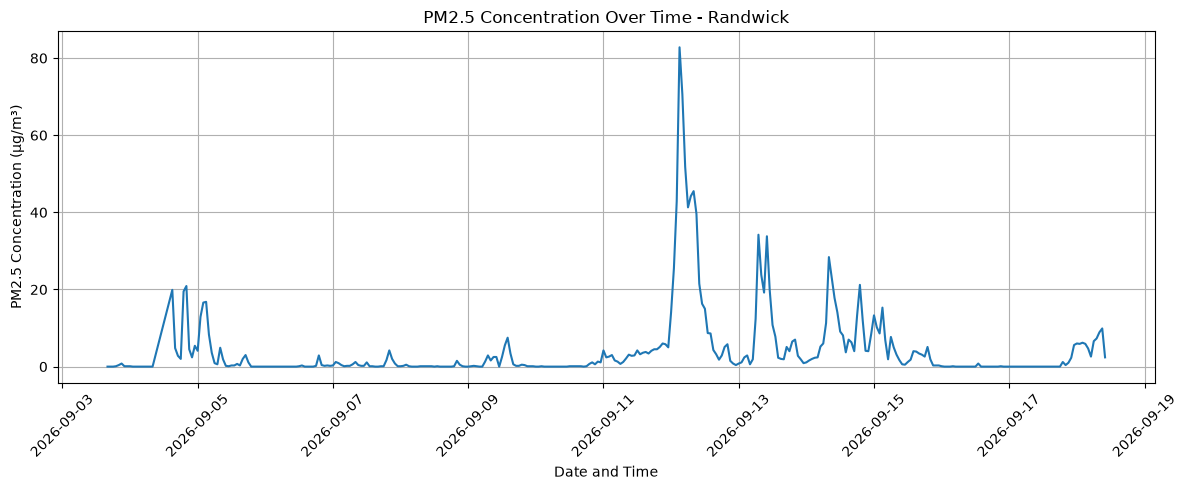

In [12]:
# Plot PM2.5 levels over time

plt.figure(figsize=(12, 5))

plt.plot(air_data["datetimeLocal"], air_data["pm25"])

plt.title("PM2.5 Concentration Over Time - Randwick")
plt.xlabel("Date and Time")
plt.ylabel("PM2.5 Concentration (µg/m³)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

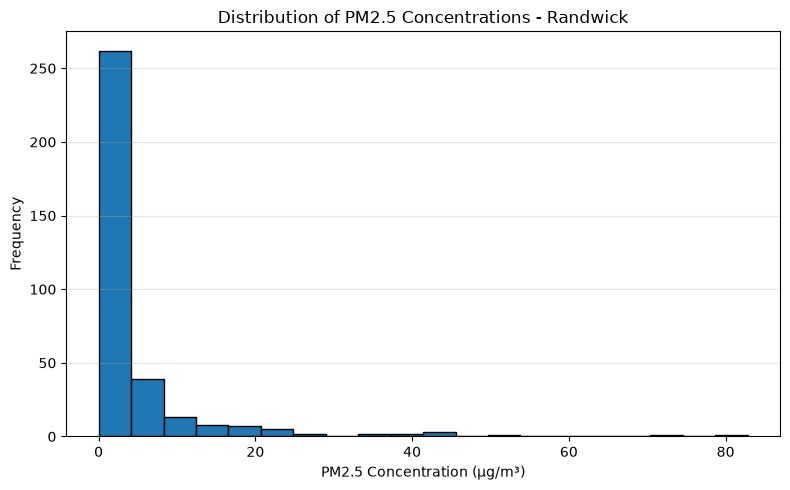

In [13]:
# Plot the distribution of PM2.5 concentrations

plt.figure(figsize=(8, 5))

plt.hist(air_data["pm25"], bins=20, edgecolor="black")

plt.title("Distribution of PM2.5 Concentrations - Randwick")
plt.xlabel("PM2.5 Concentration (µg/m³)")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

In [14]:
# Calculate correlations between numerical variables

correlation = air_data[
    ["pm1", "pm25", "relativehumidity", "temperature", "um003"]
].corr()

print("Correlation matrix:")
correlation.round(2)

Correlation matrix:


parameter,pm1,pm25,relativehumidity,temperature,um003
parameter,,,,,
pm1,1.00,0.99,0.28,-0.07,0.97
pm25,0.99,1.00,0.30,-0.07,0.98
relativehumidity,0.28,0.30,1.00,-0.60,0.31
temperature,-0.07,-0.07,-0.60,1.00,-0.03
um003,0.97,0.98,0.31,-0.03,1.00


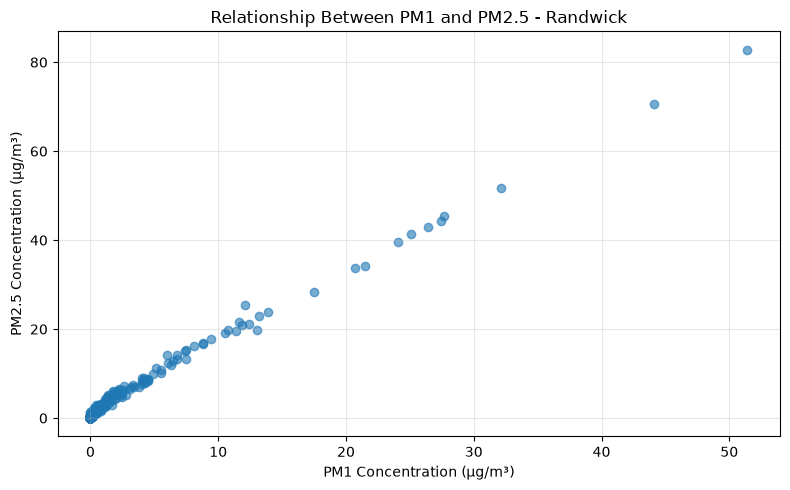

In [15]:
# Relationship between PM1 and PM2.5

plt.figure(figsize=(8, 5))

plt.scatter(air_data["pm1"], air_data["pm25"], alpha=0.6)

plt.title("Relationship Between PM1 and PM2.5 - Randwick")
plt.xlabel("PM1 Concentration (µg/m³)")
plt.ylabel("PM2.5 Concentration (µg/m³)")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

### EDA Findings

The analysis revealed that the PM2.5 levels were low for the majority of the time during the monitoring period; however, there were several short bursts of pollution in the study area. The maximum PM2.5 level reached 82.8 µg/m³, with the biggest peak of pollution happening on 12 September 2026. Also, the histogram indicated that the distribution of PM2.5 was right-skewed, which means that PM2.5 readings were quite low for most cases with only a few large values.

The correlation analysis found a very high positive correlation between PM2.5 and PM1 (r = 0.99) as well as between PM2.5 and PM0.3 particle count (r = 0.98). Relative humidity demonstrated a weaker positive correlation with PM2.5 (r = 0.30), while temperature demonstrated almost no linear correlation with PM2.5 (r = -0.07). The scatter plot of PM1 and PM2.5 illustrated the high positive correlation between the measures of particulate matter.

## 4. Predictive Modelling

Two predictive models, namely Linear Regression and Random Forest Regression were built for predicting PM2.5 levels. The choice of PM2.5 as the target variable along with PM1, Relative Humidity, Temperature and PM0.3 Particle Count as the predictor variables.

The data set was divided into training and test data with 80% of the data as training data and the remaining 20% as test data. Training data was used to build the models and test data was used to validate them.

Performance of the models was analyzed based on three criteria such as Mean Absolute Error (MAE), Root Mean Squared Error (RMSE) and R² Score. Lower MAE and RMSE indicate lower errors and high R² indicates the amount of variance in PM2.5 explained by the model.

In [16]:
# Prepare data for predictive modelling

from sklearn.model_selection import train_test_split

# Predictor variables
X = air_data[["pm1", "relativehumidity", "temperature", "um003"]]

# Target variable
y = air_data["pm25"]

# Split data: 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nPredictor variables:")
print(X.columns.tolist())

print("\nTarget variable: PM2.5")

Training records: 276
Testing records: 70

Predictor variables:
['pm1', 'relativehumidity', 'temperature', 'um003']

Target variable: PM2.5


In [17]:
# Model 1 - Linear Regression

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create and train the model
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Make predictions
linear_predictions = linear_model.predict(X_test)

# Evaluate the model
linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))
linear_r2 = r2_score(y_test, linear_predictions)

print("Linear Regression Results")
print("-------------------------")
print("MAE:", round(linear_mae, 3))
print("RMSE:", round(linear_rmse, 3))
print("R² Score:", round(linear_r2, 3))

Linear Regression Results
-------------------------
MAE: 0.62
RMSE: 1.71
R² Score: 0.987


In [18]:
# Model 2 - Random Forest Regression

from sklearn.ensemble import RandomForestRegressor

# Create and train the model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

# Make predictions
rf_predictions = rf_model.predict(X_test)

# Evaluate the model
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest Results")
print("---------------------")
print("MAE:", round(rf_mae, 3))
print("RMSE:", round(rf_rmse, 3))
print("R² Score:", round(rf_r2, 3))

Random Forest Results
---------------------
MAE: 1.299
RMSE: 5.964
R² Score: 0.846


In [19]:
# Compare predictive models

model_comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [linear_mae, rf_mae],
    "RMSE": [linear_rmse, rf_rmse],
    "R²": [linear_r2, rf_r2]
})

model_comparison.round(3)

,Model,MAE,RMSE,R²
0,Linear Regression,0.620,1.710,0.987
1,Random Forest,1.299,5.964,0.846


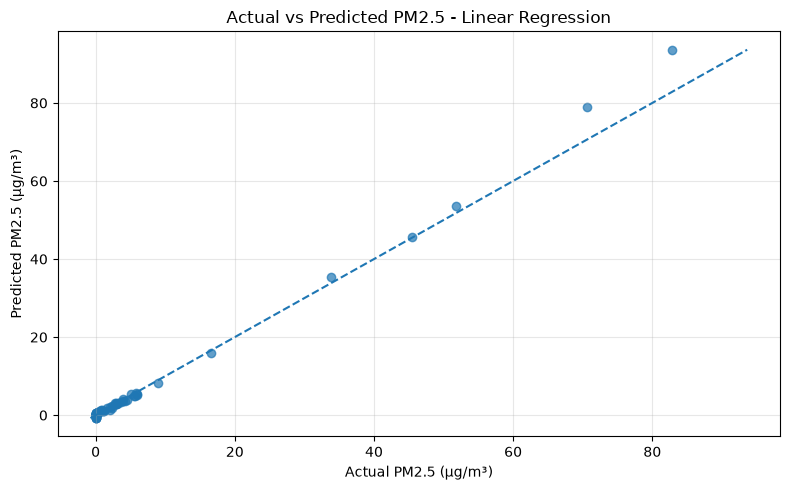

In [20]:
# Compare actual and predicted PM2.5 values

plt.figure(figsize=(8, 5))

plt.scatter(y_test, linear_predictions, alpha=0.7)

# Perfect prediction reference line
min_value = min(y_test.min(), linear_predictions.min())
max_value = max(y_test.max(), linear_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title("Actual vs Predicted PM2.5 - Linear Regression")
plt.xlabel("Actual PM2.5 (µg/m³)")
plt.ylabel("Predicted PM2.5 (µg/m³)")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

In [21]:
# Feature importance from Random Forest

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

print("Feature Importance:")
feature_importance.round(3)

Feature Importance:


,Feature,Importance
0,pm1,0.669
3,um003,0.308
2,temperature,0.017
1,relativehumidity,0.006


## 5. Model Evaluation and Key Findings

The Linear Regression model achieved an MAE of 0.620, RMSE of 1.710 and an R² score of 0.987. In comparison, the Random Forest model achieved an MAE of 1.299, RMSE of 5.964 and an R² score of 0.846. Therefore, Linear Regression produced lower prediction errors and explained a greater proportion of the variation in PM2.5 within the test dataset.

The actual-versus-predicted plot also showed that most Linear Regression predictions were close to the ideal prediction line, although larger errors were visible for some of the highest PM2.5 observations.

Random Forest feature importance showed that PM1 was the most influential predictor (66.9%), followed by PM0.3 particle count (30.8%). Temperature (1.7%) and relative humidity (0.6%) contributed comparatively little to the Random Forest predictions.

Overall, the results indicate that particulate measurements, particularly PM1 and PM0.3 particle count, were strongly associated with PM2.5 in this dataset. However, the analysis covers a relatively short monitoring period from 3 September to 18 September 2026 and data from a single Randwick monitoring location. Therefore, the model results should not automatically be generalised to other locations or longer time periods.